# Group 3 Case Study — Final Python Source Code

**Household Characteristics and Household Expenditure**  
2013 Living Costs and Food Survey (LCF)  
Group 3: Bugra · Ziad · Amal · Augustine · Nabpreet · Sharifah

This notebook retains the group’s original coding style and analysis. Requirements 1, 2 and 10 are explained in the written report.


## Requirement 3 — Data preparation and transformations

In [65]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.anova import anova_lm
from IPython.display import display


In [66]:
df = pd.read_stata('/content/LCF.dta', convert_categoricals=False)


In [67]:
df.head()

,casenew,weighta,P550tpr,P344pr,P425r,A172,A093r,A094r,A121r,SexHRP,A049r,G018r,G019r,Gorx,weightar,maininc,income,expenditure,hhsize
0,14999,2.834724,380.695762,465.36,1,1,4,3,1,2,4,2,3,4,0.543248,0,465.359985,380.695770,4
1,14993,10.077947,546.413403,855.26,1,1,1,4,3,2,2,2,1,7,1.931344,0,855.260010,546.413391,2
2,14993,4.088676,242.189023,160.96,1,1,1,2,3,2,1,1,1,8,0.783557,0,160.960007,242.189026,1
3,14984,4.571760,421.382353,656.22,1,1,1,3,3,1,2,2,1,6,0.876135,0,656.219971,421.382355,2
4,14981,7.349617,370.405577,398.80,1,1,1,4,3,1,1,1,1,8,1.408485,0,398.799988,370.405579,1


In [68]:
df.tail()

,casenew,weighta,P550tpr,P344pr,P425r,A172,A093r,A094r,A121r,SexHRP,A049r,G018r,G019r,Gorx,weightar,maininc,income,expenditure,hhsize
5139,15,9.127000,482.470833,782.040,1,1,1,2,2,2,2,2,1,2,1.749104,0,782.039978,482.470825,2
5140,15,2.750487,282.609855,612.272,2,1,4,5,3,1,2,2,1,5,0.527105,1,612.271973,282.609863,2
5141,12,4.128907,934.156186,1134.920,1,1,1,1,3,2,3,1,3,10,0.791266,0,1134.920044,934.156189,3
5142,9,2.855291,426.510540,663.669,2,1,1,2,3,1,2,2,1,2,0.547190,1,663.669006,426.510529,2
5143,1,3.264643,700.004046,1076.870,1,1,1,3,3,1,3,3,1,11,0.625638,0,1076.869995,700.004028,3


In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5144 entries, 0 to 5143
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   casenew      5144 non-null   int16  
 1   weighta      5144 non-null   float64
 2   P550tpr      5144 non-null   float64
 3   P344pr       5144 non-null   float64
 4   P425r        5144 non-null   int8   
 5   A172         5144 non-null   int8   
 6   A093r        5144 non-null   int8   
 7   A094r        5144 non-null   int8   
 8   A121r        5144 non-null   int8   
 9   SexHRP       5144 non-null   int8   
 10  A049r        5144 non-null   int8   
 11  G018r        5144 non-null   int8   
 12  G019r        5144 non-null   int8   
 13  Gorx         5144 non-null   int8   
 14  weightar     5144 non-null   float64
 15  maininc      5144 non-null   int8   
 16  income       5144 non-null   float32
 17  expenditure  5144 non-null   float32
 18  hhsize       5144 non-null   int8   
dtypes: flo

In [70]:
df.shape

(5144, 19)

In [71]:
df.isnull().sum()

,0
casenew,0
weighta,0
P550tpr,0
P344pr,0
P425r,0
A172,0
A093r,0
A094r,0
A121r,0
SexHRP,0


In [97]:
with pd.io.stata.StataReader('/content/LCF.dta') as reader:
    variable_labels = reader.variable_labels()
    value_labels = reader.value_labels()
print("VARIABLE LABELS")
for variable, label in variable_labels.items():
    print(f"{variable}: {label}")
print("\nCATEGORICAL VALUE LABELS")
for variable, labels in value_labels.items():
    print(f"\n{variable}: {labels}")

VARIABLE LABELS
casenew: New random ID number
weighta: Annual weight
P550tpr: Total expenditure (top coded)
P344pr: Gross normal weekly household income (top coded)
P425r: Main source of household income (recoded)
A172: Internet connection in household
A093r: Economic position of Household Reference Person (recoded)
A094r: NS-SEC 3 Class of Household Reference Person (recoded from NS-SEC 12)
A121r: Tenure - type (recoded)
SexHRP: Sex of Household Reference Person
A049r: Household size; number of persons in HH (recoded)
G018r: Number of adults (recoded)
G019r: Number of children (recoded)
Gorx: Government Office Region modified
weightar: Weight (rescaled)
maininc: Main source of household income (recoded, P425-1)
income: Income
expenditure: Total expenditure (top coded, formerly P550tpr)
hhsize: Household size, number of people in household (recoded)formerly A049r

CATEGORICAL VALUE LABELS

P425r: {np.int32(1): 'Earned income', np.int32(2): 'Other income'}

A172: {np.int32(1): 'Yes', np

In [73]:
independent_variables = ["A094r", "A121r", "G018r", "G019r"]

for variable in independent_variables:
    print(f"\nVariable: {variable}")
    print("Description:", variable_labels[variable])
    print("Value labels:", value_labels[variable])
    print("\nFrequency distribution:")
    print(df[variable].value_counts().sort_index())


Variable: A094r
Description: NS-SEC 3 Class of Household Reference Person (recoded from NS-SEC 12)
Value labels: {np.int32(1): 'Higher managerial, administrative and professional occupations', np.int32(2): 'Intermediate occupations', np.int32(3): 'Routine and manual occupations', np.int32(4): 'Never worked and long term unemployed, students and occupation not stated', np.int32(5): 'Not classified for other reasons'}

Frequency distribution:
A094r
1    1589
2     691
3    1045
4     200
5    1619
Name: count, dtype: int64

Variable: A121r
Description: Tenure - type (recoded)
Value labels: {np.int32(1): 'Public rented', np.int32(2): 'Private rented', np.int32(3): 'Owned'}

Frequency distribution:
A121r
1     880
2     798
3    3466
Name: count, dtype: int64

Variable: G018r
Description: Number of adults (recoded)
Value labels: {np.int32(1): '1 adult', np.int32(2): '2 adults', np.int32(3): '3 adults', np.int32(4): '4 and more adults'}

Frequency distribution:
G018r
1    1729
2    2826
3 

In [74]:

df_analysis = df.copy()
independent_variables = ["A094r", "A121r", "G018r", "G019r"]
for col in independent_variables:
    df_analysis[col] = df_analysis[col].astype("category")
dependent_variable = "expenditure"
print(df_analysis[independent_variables + [dependent_variable]].dtypes)

A094r          category
A121r          category
G018r          category
G019r          category
expenditure     float32
dtype: object


## Requirement 4 — Variables of interest and types

In [75]:

variables_of_interest = ["expenditure", "A094r", "A121r", "G018r", "G019r"]
evidence = []
for var in variables_of_interest:
    evidence.append({
        "Variable": var,
        "Description": variable_labels.get(var, ""),
        "Python Data Type": str(df_analysis[var].dtype),
        "Unique Values": df_analysis[var].nunique(),
        "Value Labels": value_labels.get(var, "No categorical value labels")})
classification_evidence = pd.DataFrame(evidence)
display(classification_evidence)


,Variable,Description,Python Data Type,Unique Values,Value Labels
0,expenditure,"Total expenditure (top coded, formerly P550tpr)",float32,4887,No categorical value labels
1,A094r,NS-SEC 3 Class of Household Reference Person (...,category,5,"{1: 'Higher managerial, administrative and pro..."
2,A121r,Tenure - type (recoded),category,3,"{1: 'Public rented', 2: 'Private rented', 3: '..."
3,G018r,Number of adults (recoded),category,4,"{1: '1 adult', 2: '2 adults', 3: '3 adults', 4..."
4,G019r,Number of children (recoded),category,3,"{1: 'No children', 2: 'One child', 3: 'Two or ..."


In [76]:
dependent_variable = "expenditure"
independent_variables = ["A094r", "A121r", "G018r", "G019r"]
variables_of_interest = [dependent_variable] + independent_variables
variable_summary = pd.DataFrame({
    "Variable": variables_of_interest,
    "Description": [variable_labels[var] for var in variables_of_interest],
    "Python Data Type": [str(df_analysis[var].dtype) for var in variables_of_interest],
    "Statistical Type": ["Quantitative (Continuous)","Nominal","Nominal","Ordinal","Ordinal"],
    "Role": ["Dependent","Independent","Independent","Independent","Independent"]})
display(variable_summary)

,Variable,Description,Python Data Type,Statistical Type,Role
0,expenditure,"Total expenditure (top coded, formerly P550tpr)",float32,Quantitative (Continuous),Dependent
1,A094r,NS-SEC 3 Class of Household Reference Person (...,category,Nominal,Independent
2,A121r,Tenure - type (recoded),category,Nominal,Independent
3,G018r,Number of adults (recoded),category,Ordinal,Independent
4,G019r,Number of children (recoded),category,Ordinal,Independent


## Requirement 5 — Categories, meanings and sample frequencies

In [77]:

categorical_variables = ["A094r", "A121r", "G018r", "G019r"]
category_records = []
for var in categorical_variables:
    for code, meaning in value_labels[var].items():
        category_records.append({
            "Variable": var,
            "Description": variable_labels[var],
            "Code": int(code),
            "Category Meaning": meaning,
            "Household Count": int((df[var] == code).sum())})
category_summary = pd.DataFrame(category_records)
display(category_summary)

,Variable,Description,Code,Category Meaning,Household Count
0,A094r,NS-SEC 3 Class of Household Reference Person (...,1,"Higher managerial, administrative and professi...",1589
1,A094r,NS-SEC 3 Class of Household Reference Person (...,2,Intermediate occupations,691
2,A094r,NS-SEC 3 Class of Household Reference Person (...,3,Routine and manual occupations,1045
3,A094r,NS-SEC 3 Class of Household Reference Person (...,4,"Never worked and long term unemployed, student...",200
4,A094r,NS-SEC 3 Class of Household Reference Person (...,5,Not classified for other reasons,1619
5,A121r,Tenure - type (recoded),1,Public rented,880
6,A121r,Tenure - type (recoded),2,Private rented,798
7,A121r,Tenure - type (recoded),3,Owned,3466
8,G018r,Number of adults (recoded),1,1 adult,1729
9,G018r,Number of adults (recoded),2,2 adults,2826


## Requirement 6 — Analysis selected and rationale

OLS is fitted with four categorical predictors, using the lowest coded category as each reference. The primary model is unweighted and additive.

In [78]:

weight_variables = ["weighta", "weightar"]
display(df_analysis[weight_variables].describe())
print("Missing weight values:")
display(df_analysis[weight_variables].isnull().sum())
print("Zero or negative weights:")
print((df_analysis[weight_variables] <= 0).sum())

,weighta,weightar
count,5144.000000,5144.000000
mean,5.218090,0.999998
std,1.783115,0.341717
min,0.001000,0.000192
25%,4.088583,0.783539
50%,4.919582,0.942792
75%,5.967865,1.143685
max,24.500000,4.695196


Missing weight values:


,0
weighta,0
weightar,0


Zero or negative weights:
weighta     0
weightar    0
dtype: int64


In [79]:

weight_ratio = df_analysis["weighta"] / df_analysis["weightar"]
print("Weight ratio summary:")
display(weight_ratio.describe())
print("Correlation between weights:", df_analysis["weighta"].corr(df_analysis["weightar"]))
print("Sum of rescaled weights:", df_analysis["weightar"].sum())

Weight ratio summary:


,0
count,5.144000e+03
mean,5.218100e+00
std,6.599773e-13
min,5.218100e+00
25%,5.218100e+00
50%,5.218100e+00
75%,5.218100e+00
max,5.218100e+00


Correlation between weights: 1.0
Sum of rescaled weights: 5143.9900785440805


In [80]:

formula = ("expenditure ~ C(A094r) + C(A121r) ""+ C(G018r) + C(G019r)")
ols_model = smf.ols(formula=formula,data=df_analysis).fit()
print(ols_model.summary())


                            OLS Regression Results                            
Dep. Variable:            expenditure   R-squared:                       0.412
Model:                            OLS   Adj. R-squared:                  0.411
Method:                 Least Squares   F-statistic:                     327.5
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:41:53   Log-Likelihood:                -35139.
No. Observations:                5144   AIC:                         7.030e+04
Df Residuals:                    5132   BIC:                         7.038e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept       340.5412     11.243     30.288

## Requirement 7 — Regression assumptions and diagnostic checks

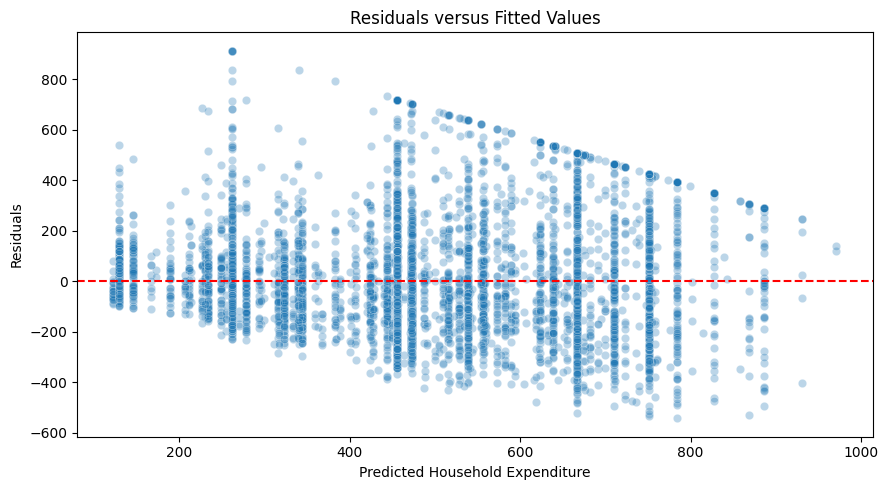

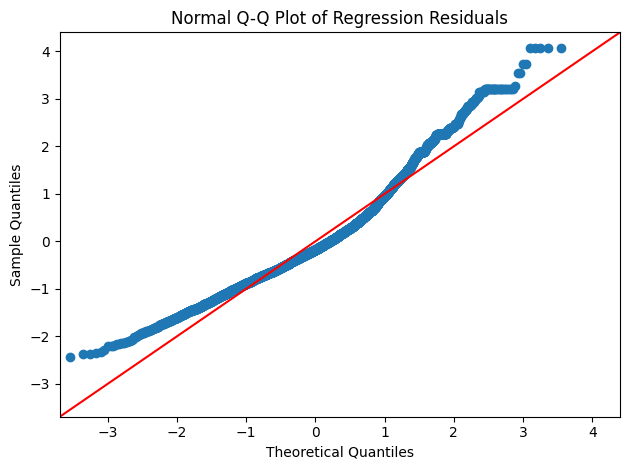

Breusch-Pagan Test Results
LM Statistic: 272.4067
LM p-value: 5.58602e-52
F Statistic: 26.0880
F p-value: 1.8274e-53


In [81]:

fitted_values = ols_model.fittedvalues
residuals = ols_model.resid
plt.figure(figsize=(9, 5))
sns.scatterplot(x=fitted_values,y=residuals,alpha=0.3)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals versus Fitted Values")
plt.xlabel("Predicted Household Expenditure")
plt.ylabel("Residuals")
plt.tight_layout()
plt.show()
sm.qqplot(residuals, line="45", fit=True)
plt.title("Normal Q-Q Plot of Regression Residuals")
plt.tight_layout()
plt.show()
bp_test = het_breuschpagan(residuals,ols_model.model.exog)
print("Breusch-Pagan Test Results")
print(f"LM Statistic: {bp_test[0]:.4f}")
print(f"LM p-value: {bp_test[1]:.6g}")
print(f"F Statistic: {bp_test[2]:.4f}")
print(f"F p-value: {bp_test[3]:.6g}")


In [82]:

ols_robust = ols_model.get_robustcov_results(cov_type="HC3")
print(ols_robust.summary())
print(f"Breusch-Pagan LM p-value: {bp_test[1]:.8g}")
print(f"Breusch-Pagan F p-value: {bp_test[3]:.8g}")


                            OLS Regression Results                            
Dep. Variable:            expenditure   R-squared:                       0.412
Model:                            OLS   Adj. R-squared:                  0.411
Method:                 Least Squares   F-statistic:                     392.2
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:41:53   Log-Likelihood:                -35139.
No. Observations:                5144   AIC:                         7.030e+04
Df Residuals:                    5132   BIC:                         7.038e+04
Df Model:                          11                                         
Covariance Type:                  HC3                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept       340.5412     10.233     33.277

In [83]:

X = ols_model.model.exog
variable_names = ols_model.model.exog_names
vif_results = pd.DataFrame({
    "Variable": variable_names,
    "VIF": [variance_inflation_factor(X, i) for i in range(X.shape[1])]})
display(vif_results)


,Variable,VIF
0,Intercept,1.000000
1,C(A094r)[T.2],1.258415
2,C(A094r)[T.3],1.411351
3,C(A094r)[T.4],1.168640
4,C(A094r)[T.5],1.660119
5,C(A121r)[T.2],1.684634
6,C(A121r)[T.3],1.827703
7,C(G018r)[T.2],1.327182
8,C(G018r)[T.3],1.199677
9,C(G018r)[T.4],1.082139


Design matrix rank: 12
Number of columns: 12
Full rank: True

Cook's Distance Summary
Maximum Cook's distance: 0.00547929379186767
Screening threshold (4/n): 0.0007776049766718507
Observations above threshold: 324


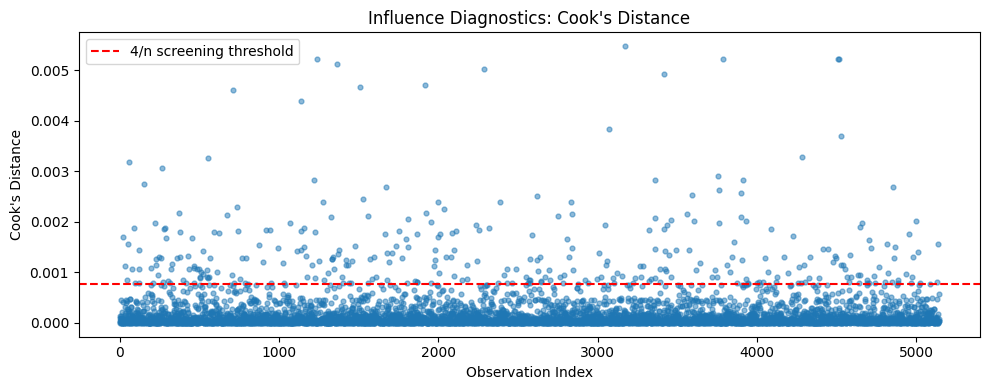

In [84]:
X = ols_model.model.exog
matrix_rank = np.linalg.matrix_rank(X)
number_of_columns = X.shape[1]
print("Design matrix rank:", matrix_rank)
print("Number of columns:", number_of_columns)
print("Full rank:", matrix_rank == number_of_columns)
influence = ols_model.get_influence()
cooks_distance = influence.cooks_distance[0]
threshold = 4 / len(df_analysis)
print("\nCook's Distance Summary")
print("Maximum Cook's distance:", cooks_distance.max())
print("Screening threshold (4/n):", threshold)
print("Observations above threshold:", (cooks_distance > threshold).sum())
plt.figure(figsize=(10, 4))
plt.scatter(range(len(cooks_distance)),cooks_distance,alpha=0.5,s=12)
plt.axhline(threshold, color="red", linestyle="--", label="4/n screening threshold")
plt.xlabel("Observation Index")
plt.ylabel("Cook's Distance")
plt.title("Influence Diagnostics: Cook's Distance")
plt.legend()
plt.tight_layout()
plt.show()

In [85]:

keep_mask = cooks_distance <= threshold
sensitivity_model = smf.ols(
    formula=formula,
    data=df_analysis.loc[keep_mask]).fit(cov_type="HC3")
coefficient_comparison = pd.DataFrame({
    "Original OLS": ols_model.params,
    "Sensitivity OLS": sensitivity_model.params})
coefficient_comparison["Absolute Difference"] = (
    coefficient_comparison["Sensitivity OLS"]
    - coefficient_comparison["Original OLS"]).abs()
display(coefficient_comparison)
print("Original observations:", len(df_analysis))
print("Sensitivity observations:", keep_mask.sum())
print("Original R-squared:", round(ols_model.rsquared, 4))
print("Sensitivity R-squared:", round(sensitivity_model.rsquared, 4))


,Original OLS,Sensitivity OLS,Absolute Difference
Intercept,340.541247,356.735449,16.194202
C(A094r)[T.2],-128.364613,-151.177572,22.812958
C(A094r)[T.3],-194.900655,-202.290063,7.389408
C(A094r)[T.4],-217.521003,-256.175012,38.654008
C(A094r)[T.5],-210.855448,-232.238603,21.383154
C(A121r)[T.2],103.964485,70.124858,33.839628
C(A121r)[T.3],132.510830,116.878063,15.632767
C(G018r)[T.2],193.754936,185.946997,7.807939
C(G018r)[T.3],310.752013,299.008234,11.743778
C(G018r)[T.4],413.582318,414.467848,0.885530


Original observations: 5144
Sensitivity observations: 4820
Original R-squared: 0.4124
Sensitivity R-squared: 0.4982


In [86]:

interaction_model = smf.ols(
    formula=(
        "expenditure ~ C(A094r) + C(A121r) "
        "+ C(G018r) * C(G019r)"),
    data=df_analysis).fit()
model_comparison = anova_lm(ols_model,interaction_model)
display(model_comparison)
print("Original model R-squared:", round(ols_model.rsquared, 4))
print("Interaction model R-squared:", round(interaction_model.rsquared, 4))
print("Original model AIC:", round(ols_model.aic, 2))
print("Interaction model AIC:", round(interaction_model.aic, 2))


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,5132.0,2.583087e+08,0.0,NaN,NaN,NaN
1,5126.0,2.579923e+08,6.0,316417.003777,1.047805,0.391987


Original model R-squared: 0.4124
Interaction model R-squared: 0.4131
Original model AIC: 70301.11
Interaction model AIC: 70306.8


In [87]:

interaction_robust = interaction_model.get_robustcov_results(cov_type="HC3")
interaction_terms = [name for name in interaction_model.model.exog_names if ":" in name]
print("Interaction terms:")
print(interaction_terms)
hypothesis = " , ".join(f"{term} = 0" for term in interaction_terms)
robust_interaction_test = interaction_robust.f_test(hypothesis)
print("\nHC3 robust joint interaction test:")
print(robust_interaction_test)


Interaction terms:
['C(G018r)[T.2]:C(G019r)[T.2]', 'C(G018r)[T.3]:C(G019r)[T.2]', 'C(G018r)[T.4]:C(G019r)[T.2]', 'C(G018r)[T.2]:C(G019r)[T.3]', 'C(G018r)[T.3]:C(G019r)[T.3]', 'C(G018r)[T.4]:C(G019r)[T.3]']

HC3 robust joint interaction test:
<F test: F=0.8201690911997906, p=0.5540399903854378, df_denom=5.13e+03, df_num=6>


## Requirement 8 — Null and alternative hypotheses

In [88]:

alpha = 0.05
print("HC3 robust overall F-statistic:", ols_robust.fvalue)
print("HC3 robust overall p-value:", ols_robust.f_pvalue)
if ols_robust.f_pvalue < alpha:
    print("Decision: Reject H0")
    print("At least one household characteristic is associated with expenditure.")
else:
    print("Decision: Fail to reject H0")


HC3 robust overall F-statistic: 392.21716512495203
HC3 robust overall p-value: 0.0
Decision: Reject H0
At least one household characteristic is associated with expenditure.


## Requirement 9 — Results and answer to the research question

### 9.1 Descriptive statistics

Household expenditure summary:


,expenditure
count,5144.000000
mean,479.758423
std,292.364960
min,30.525000
25%,254.127823
50%,419.903442
75%,644.974411
max,1175.000000


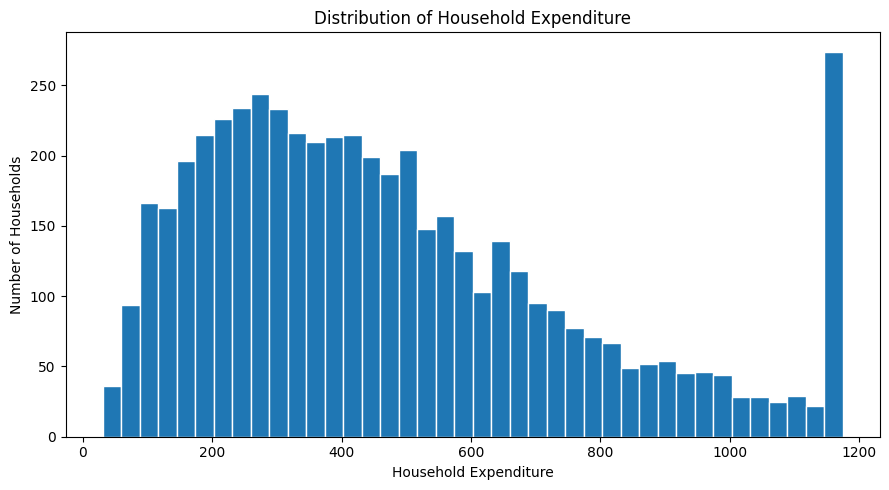

Zero or negative expenditure values: 0


In [89]:

print("Household expenditure summary:")
display(df_analysis["expenditure"].describe())
plt.figure(figsize=(9, 5))
plt.hist(df_analysis["expenditure"], bins=40, edgecolor="white")
plt.title("Distribution of Household Expenditure")
plt.xlabel("Household Expenditure")
plt.ylabel("Number of Households")
plt.tight_layout()
plt.show()
print("Zero or negative expenditure values:", (df_analysis["expenditure"] <= 0).sum())

In [90]:

maximum_expenditure = df_analysis["expenditure"].max()
households_at_max = (df_analysis["expenditure"] == maximum_expenditure).sum()
percentage_at_max = (households_at_max / len(df_analysis)) * 100
print("Maximum recorded expenditure:", maximum_expenditure)
print("Households at maximum:", households_at_max)
print("Percentage at maximum:", round(percentage_at_max, 2))
print("Expenditure skewness:", round(df_analysis["expenditure"].skew(), 3))

Maximum recorded expenditure: 1175.0
Households at maximum: 256
Percentage at maximum: 4.98
Expenditure skewness: 0.826


In [91]:
# Table 1: Unadjusted mean household expenditure by household characteristics
category_labels = {
    'A094r': ['Higher managerial / professional', 'Intermediate', 'Routine / manual',
              'Never worked / unemployed / student / not stated', 'Other not classified'],
    'A121r': ['Public rented', 'Private rented', 'Owned'],
    'G018r': ['1 adult', '2 adults', '3 adults', '4+ adults'],
    'G019r': ['No children', '1 child', '2+ children']}
characteristic_names = {'A094r': 'Occupation', 'A121r': 'Tenure',
                        'G018r': 'Adults', 'G019r': 'Children'}
mean_records = []
for variable, labels in category_labels.items():
    means = df_analysis.groupby(variable, observed=True)['expenditure'].mean()
    for code_value, label in enumerate(labels, start=1):
        mean_records.append({'Characteristic': characteristic_names[variable],
                             'Group': label,
                             'Mean expenditure (£)': round(means.loc[code_value], 2)})
mean_expenditure_table = pd.DataFrame(mean_records)
print('Table 1. Unadjusted Mean Household Expenditure by Household Characteristics')
display(mean_expenditure_table)


Table 1. Unadjusted Mean Household Expenditure by Household Characteristics


,Characteristic,Group,Mean expenditure (£)
0,Occupation,Higher managerial / professional,664.520020
1,Occupation,Intermediate,501.059998
2,Occupation,Routine / manual,420.950012
3,Occupation,Never worked / unemployed / student / not stated,349.269989
4,Occupation,Other not classified,343.410004
5,Tenure,Public rented,284.929993
6,Tenure,Private rented,472.390015
7,Tenure,Owned,530.919983
8,Adults,1 adult,285.470001
9,Adults,2 adults,553.390015


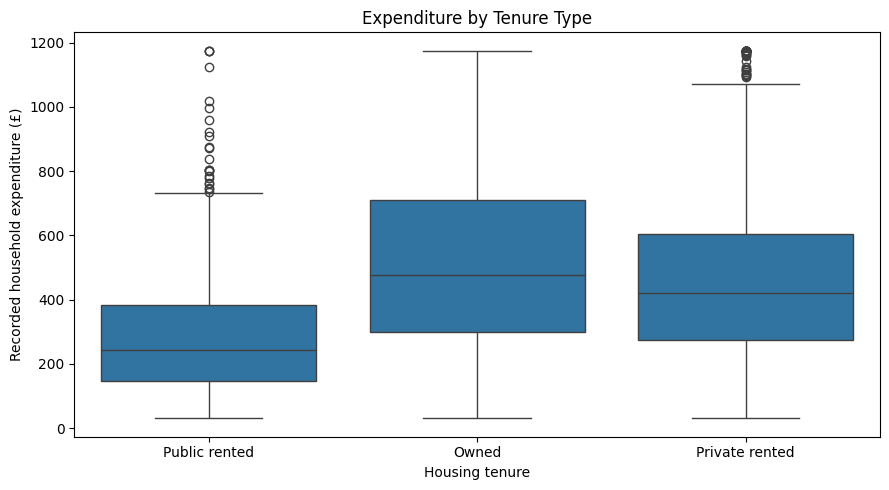

In [92]:
# Figure 5: Expenditure by housing tenure (unadjusted boxplot)
tenure_labels = {1: 'Public rented', 2: 'Private rented', 3: 'Owned'}
tenure_order = ['Public rented', 'Owned', 'Private rented']
df_analysis['Tenure type'] = df_analysis['A121r'].astype(int).map(tenure_labels)
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_analysis, x='Tenure type', y='expenditure', order=tenure_order)
plt.title('Expenditure by Tenure Type')
plt.xlabel('Housing tenure')
plt.ylabel('Recorded household expenditure (£)')
plt.tight_layout()
plt.show()


### 9.2–9.3 Overall regression and robust joint significance tests

In [93]:

alpha = 0.05
independent_variables = {
    "Occupational class": "A094r",
    "Tenure type": "A121r",
    "Number of adults": "G018r",
    "Number of children": "G019r"}
coefficient_names = ols_model.model.exog_names
for label, variable in independent_variables.items():
    terms = [name for name in coefficient_names if name.startswith(f"C({variable})[T.")]
    hypothesis = " , ".join(f"{term} = 0" for term in terms)
    test = ols_robust.f_test(hypothesis)
    f_statistic = float(test.fvalue)
    p_value = float(test.pvalue)
    print(f"\n{label}")
    print("-" * 45)
    print(f"Number of coefficients tested: {len(terms)}")
    print(f"HC3 robust F-statistic: {f_statistic:.4f}")
    print(f"P-value: {p_value:.6g}")
    if p_value < alpha:
        print("Decision: Reject H0")
        print("This variable is jointly significant.")
    else:
        print("Decision: Fail to reject H0")
        print("Insufficient evidence of a joint association.")



Occupational class
---------------------------------------------
Number of coefficients tested: 4
HC3 robust F-statistic: 160.4637
P-value: 1.35164e-129
Decision: Reject H0
This variable is jointly significant.

Tenure type
---------------------------------------------
Number of coefficients tested: 2
HC3 robust F-statistic: 185.1746
P-value: 2.23347e-78
Decision: Reject H0
This variable is jointly significant.

Number of adults
---------------------------------------------
Number of coefficients tested: 3
HC3 robust F-statistic: 431.7566
P-value: 4.06529e-250
Decision: Reject H0
This variable is jointly significant.

Number of children
---------------------------------------------
Number of coefficients tested: 2
HC3 robust F-statistic: 41.5826
P-value: 1.21806e-18
Decision: Reject H0
This variable is jointly significant.


### 9.4 Adjusted regression coefficients and confidence intervals

In [94]:
# Table 3: Adjusted OLS coefficients, HC3 robust SEs, 95% confidence intervals
ci = ols_robust.conf_int(alpha=0.05)
coefficient_table = pd.DataFrame({
    'Predictor category': ols_model.model.exog_names,
    'Coefficient (£)': ols_robust.params,
    'HC3 SE': ols_robust.bse,
    '95% CI lower (£)': ci[:, 0],
    '95% CI upper (£)': ci[:, 1],
    'p-value': ols_robust.pvalues})
print('Table 3. Adjusted OLS Regression Coefficients with HC3 Robust Standard Errors and 95% Confidence Intervals')
display(coefficient_table.round(4))


Table 3. Adjusted OLS Regression Coefficients with HC3 Robust Standard Errors and 95% Confidence Intervals


,Predictor category,Coefficient (£),HC3 SE,95% CI lower (£),95% CI upper (£),p-value
0,Intercept,340.5412,10.2334,320.4794,360.6031,0.0
1,C(A094r)[T.2],-128.3646,10.7646,-149.4678,-107.2614,0.0
2,C(A094r)[T.3],-194.9007,9.1440,-212.8268,-176.9745,0.0
3,C(A094r)[T.4],-217.5210,16.9764,-250.8020,-184.2400,0.0
4,C(A094r)[T.5],-210.8554,9.2764,-229.0412,-192.6697,0.0
5,C(A121r)[T.2],103.9645,9.5650,85.2129,122.7160,0.0
6,C(A121r)[T.3],132.5108,6.9845,118.8182,146.2035,0.0
7,C(G018r)[T.2],193.7549,6.6034,180.8094,206.7005,0.0
8,C(G018r)[T.3],310.7520,13.8771,283.5470,337.9571,0.0
9,C(G018r)[T.4],413.5823,21.6010,371.2352,455.9294,0.0


In [95]:

print("MULTIPLE LINEAR REGRESSION RESULTS")
print("=" * 60)
print(ols_robust.summary())


MULTIPLE LINEAR REGRESSION RESULTS
                            OLS Regression Results                            
Dep. Variable:            expenditure   R-squared:                       0.412
Model:                            OLS   Adj. R-squared:                  0.411
Method:                 Least Squares   F-statistic:                     392.2
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:41:54   Log-Likelihood:                -35139.
No. Observations:                5144   AIC:                         7.030e+04
Df Residuals:                    5132   BIC:                         7.038e+04
Df Model:                          11                                         
Covariance Type:                  HC3                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept  